In [41]:
import pandas
from datascience import *
import numpy as np
%matplotlib inline

In [4]:
winedata = Table.read_table('data/wine_price_vs_blind_quality.csv')
datadic = Table.read_table('data/data_dictionary (2).csv')
#getting the orginal table read

winedata.show(10)
datadic.show()

wine_id,region,grape,price,vintage_quality,winemaking_score,region_prestige,region_terroir,scarcity,oak_months,residual_sugar,alcohol,true_quality,blind_rating_expert,blind_rating_novice,blind_rating,sighted_rating,overpriced,value_wine
WIN000000,generic_new_world,blend,8.59,7.36,1.88,3,5,4.81,3,5,12.7,79.6,79,91.8,85.4,79.3,0,1
WIN000001,Mendoza,malbec,49.25,3.76,4.76,5,6,8.67,18,2.1,14.6,78.8,74.7,84.1,79.4,84,1,0
WIN000002,Tuscany,sangiovese,8.24,7.02,0.18,7,7,3.6,6,12.9,12.5,80.8,81,86,83.5,80.1,0,0
WIN000003,Tuscany,sangiovese,18.99,7.5,5.4,7,7,5.7,10,2.8,13.9,85.5,82.9,87.3,85.1,83.7,0,0
WIN000004,Mendoza,sangiovese,57.69,2.86,3.92,5,6,9.85,17,1,15.2,76,76.7,72.1,74.4,77.8,1,0
WIN000005,Burgundy,shiraz,35.04,6.6,6.99,9,8,6.94,2,3.6,12.1,89.3,89.2,89.3,89.2,89.2,0,0
WIN000006,Rioja,pinot_noir,19.73,4.56,3.99,6,6,3.26,15,4.1,11.2,80.3,81.1,80,80.6,80,0,0
WIN000007,Burgundy,cab_sauv,22.54,7.84,5.35,9,8,8.26,2,3.9,15.1,88.9,91.5,87.9,89.7,88.2,0,0
WIN000008,Mendoza,pinot_noir,8.85,4.78,3.29,5,6,1.81,21,4.5,15,80.4,82.7,75.5,79.1,74.4,0,0
WIN000009,Rioja,sangiovese,10.66,7.81,1.41,6,6,3.33,22,1.7,14.2,83,83.6,78.1,80.8,76.4,0,0


column,type,description
wine_id,string,Unique wine id
region,string,"Wine region (Bordeaux, Napa, Burgundy, Rioja, Tuscany, B ..."
grape,string,Primary grape variety
price,float,Retail price (USD) — driven mostly by region prestige & ...
vintage_quality,float,QUALITY: weather/vintage conditions (0-10)
winemaking_score,float,QUALITY: winemaking craft (0-10)
region_prestige,float,PRICE driver: reputation of the region (0-10)
region_terroir,float,QUALITY driver: terroir potential of the region (0-10)
scarcity,float,PRICE driver: limited production / rarity (0-10)
oak_months,int,Months in oak


In [16]:
#Question 1: How much does a wine's rating change when its price is revealed?
#Part 1: Average change
Q1 = winedata.select('wine_id','blind_rating', 'sighted_rating')
diff = Q1.apply(np.subtract, 'sighted_rating', 'blind_rating')

Q1 = Q1.with_column('rating_diff', diff)
Q1 #This table shows the difference between the sighted and blind ratings

wine_id,blind_rating,sighted_rating,rating_diff
WIN000000,85.4,79.3,-6.1
WIN000001,79.4,84,4.6
WIN000002,83.5,80.1,-3.4
WIN000003,85.1,83.7,-1.4
WIN000004,74.4,77.8,3.4
WIN000005,89.2,89.2,0
WIN000006,80.6,80,-0.6
WIN000007,89.7,88.2,-1.5
WIN000008,79.1,74.4,-4.7
WIN000009,80.8,76.4,-4.4


In [24]:
#What is the signed average difference?
signed_avg_diff = np.average(Q1.column('rating_diff'))
signed_avg_diff

0.027044999999999975

In [25]:
#What is the absolute average difference?

In [33]:
abs_array = np.abs(Q1.column('rating_diff'))
abs_avg_diff = np.average(abs_array)
abs_avg_diff

2.3855949999999999

In [38]:
#The signed average difference shows ratings are nearly unchnaged on average when price is shown, however,
#the absolute average difference being 2.39 shows that the rating are changing and the positive vs negative
#may be cancelling each other out. A histograph will show if the changes are all around 0 or if they're substantially
#positve and negative

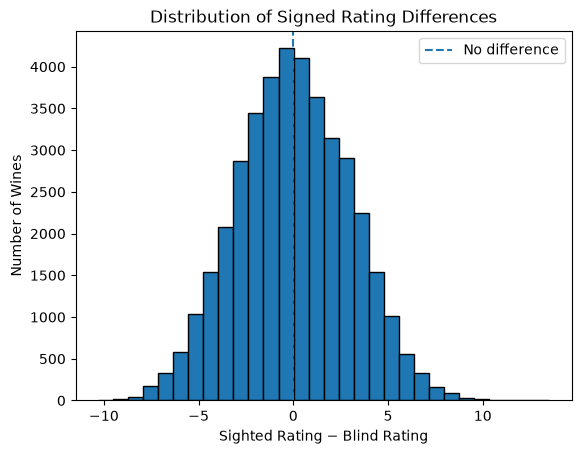

In [53]:
import matplotlib.pyplot as plt

plt.hist(Q1.column('rating_diff'), bins=30, edgecolor="black")

plt.axvline(0, linestyle="--", label="No difference")

plt.xlabel("Sighted Rating − Blind Rating")
plt.ylabel("Number of Wines")
plt.title("Distribution of Signed Rating Differences")
plt.legend()

plt.show()

In [55]:
#This graph shows that most differences are close to 0, showing that most wines only have a small rating change
#when price is shown.

In [57]:
#Calculate the standard deviation to help back that up
std_dev = (Q1.column('rating_diff')).std()
std_dev

2.9671377736760052

In [58]:
#The standard deviation is relatively small on the 100 point scale, consistant with most changes being small.

In [59]:
#Question 1, Part 2: Does rating change depend on price?
#use regression to fi